# X-IIoTID — 06. Signature-disjoint split + first ML baseline

**J26-CS-336 · Network Flow V2 · Primary-dataset candidate**

**Goal:** Move from repetitive audits to actual model development. Reuse the verified **Notebook 04** SQLite signature counts for a provisional **70/15/15 split**. Ensure **no Core-19 identical-feature group appears in more than one partition**, learn preprocessing **from training only**, train a **Decision Tree**, compare it with a **missingness-only** baseline, and plot validation metrics.

**Important limitations:** The 19 candidate features have **not yet been verified** as edge-gateway extractable or semantically equivalent across datasets. Grouping by 19-field signature blocks exact-input overlap, but **does not establish session/campaign independence**. We do **not** evaluate the reserved test set in this notebook, and we make **no claim of full APT-campaign detection**.

**Required:** Notebook 04's `data/interim/x_iiotid_full_collision_gate_v1.sqlite` and the original local X-IIoTID CSV. **Do not commit either.**

In [1]:
from pathlib import Path
from collections import Counter
import hashlib, json, os, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, balanced_accuracy_score,
                             precision_score, recall_score, f1_score)

GIT_ROOT = Path(r'D:\J26-CS-336-Network-Flow-V2-Git\network_flow_v2')
OLD_ROOT = Path(r'D:\J26-CS-336-Network-Flow-V2\network_flow_v2')
ROOT = Path(os.environ.get('NETWORK_FLOW_V2_ROOT', str(GIT_ROOT)))
if not ROOT.is_dir():
    raise FileNotFoundError(f'Open the Git-connected V2 folder: {ROOT}')
CSV = ROOT / 'data/raw/x_iiotid/X-IIoTID dataset.csv'
if not CSV.is_file():
    CSV = OLD_ROOT / 'data/raw/x_iiotid/X-IIoTID dataset.csv'
DB = ROOT / 'data/interim/x_iiotid_full_collision_gate_v1.sqlite'
if not CSV.is_file() or not DB.is_file():
    raise FileNotFoundError('Missing raw CSV or Notebook 04 SQLite database. Complete Notebook 04 first.')
FIG = ROOT/'reports/figures'; AUDIT = ROOT/'reports/audits'; SPLITS=ROOT/'data/splits'; DOCS=ROOT/'docs'
for d in (FIG,AUDIT,SPLITS,DOCS): d.mkdir(parents=True,exist_ok=True)
SEED=42
PLACEHOLDERS={'', '-', '?', 'n/a', 'na', 'nan', 'none', 'null', 'missing', 'unknown'}
CORE19=['Protocol','Service','Duration','Scr_bytes','Des_bytes','Conn_state',
        'is_syn_only','Is_SYN_ACK','is_pure_ack','is_with_payload','FIN or RST',
        'Scr_pkts','Scr_ip_bytes','Des_pkts','Des_ip_bytes','total_bytes',
        'total_packet','paket_rate','byte_rate']
CAT=['Protocol','Service','Conn_state','is_syn_only','Is_SYN_ACK','is_pure_ack','is_with_payload','FIN or RST']
NUM=[c for c in CORE19 if c not in CAT]
TARGET_BINARY='class3'; TARGET_STAGE='class2'
assert len(CORE19)==19 and len(NUM)==11 and len(CAT)==8
print('CSV:', CSV)
print('Notebook 04 signature DB:',DB)
print('Figures/reports:', ROOT)
print('No raw rows will be committed.')

CSV: D:\J26-CS-336-Network-Flow-V2-Git\network_flow_v2\data\raw\x_iiotid\X-IIoTID dataset.csv
Notebook 04 signature DB: D:\J26-CS-336-Network-Flow-V2-Git\network_flow_v2\data\interim\x_iiotid_full_collision_gate_v1.sqlite
Figures/reports: D:\J26-CS-336-Network-Flow-V2-Git\network_flow_v2
No raw rows will be committed.


## A. Assign **entire input-signature groups** to 70/15/15 partitions

The SQLite database has one row per **distinct 19-feature signature** with Normal and Attack counts. We assign a signature to **exactly one** partition. The largest group goes into training to avoid one signature dominating a holdout. This is a reproducible greedy **binary-stratified group split**, not a claim of capture-session independence. The notebook fails if the split misses its ratio tolerances.

,Normal,Attack,rows,row_fraction,attack_fraction
train,294992,279593,574585,0.700001,0.486600
validation,63213,59912,123125,0.150000,0.486595
test,63212,59912,123124,0.149999,0.486599


Unique Core-19 groups: 419,378; rows: 820,834
PASS: approximate 70/15/15 partition sizes and binary class coverage


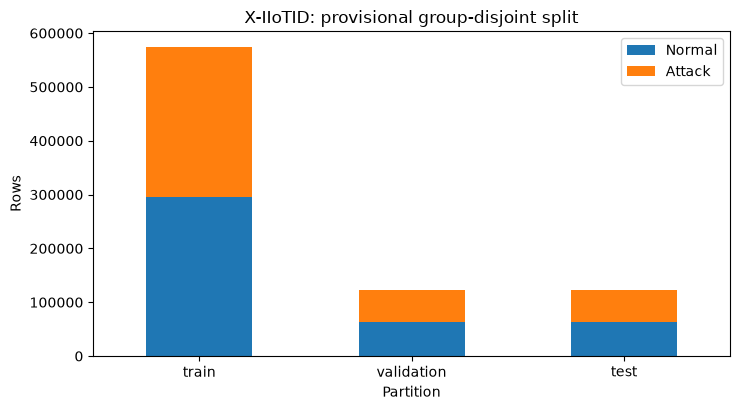

In [2]:
con=sqlite3.connect(str(DB))
actual_tables={r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type='table'")}
assert 'core19' in actual_tables, f'core19 table absent: {actual_tables}'
groups=con.execute("""SELECT signature, normal_count, attack_count FROM core19
                    ORDER BY (normal_count+attack_count) DESC, signature""").fetchall()
con.close()
assert groups and len(groups)==len({g[0] for g in groups})
total_normal=sum(int(g[1]) for g in groups)
total_attack=sum(int(g[2]) for g in groups)
N=total_normal+total_attack
TARGET_RATIOS={'train':.70,'validation':.15,'test':.15}
target=np.array([[total_normal*r,total_attack*r] for r in TARGET_RATIOS.values()],dtype=float)
counts=np.zeros((3,2),dtype=np.int64)
assignment={}
part_names=list(TARGET_RATIOS)
for signature,n0,n1 in groups:
    g=np.array([int(n0),int(n1)],dtype=np.int64)
    # A group >5% of all rows would dominate a 15% validation/test subset.
    if g.sum()>0.05*N:
        chosen=0
    else:
        # Compare relative unmet binary-label targets, penalize overshooting.
        unmet=(target-counts)/np.maximum(target,1.)
        reward=(unmet@g)/max(int(g.sum()),1)
        excess=np.maximum(0,counts+g-target).sum(axis=1)/np.maximum(target.sum(axis=1),1.)
        score=reward - 20*excess
        chosen=int(np.argmax(score))
    assignment[signature]=part_names[chosen]
    counts[chosen]+=g
summary=pd.DataFrame(counts,index=part_names,columns=['Normal','Attack'])
summary['rows']=summary.sum(axis=1)
summary['row_fraction']=summary['rows']/N
summary['attack_fraction']=summary['Attack']/summary['rows']
display(summary)
print(f'Unique Core-19 groups: {len(assignment):,}; rows: {N:,}')
assert abs(summary['rows'].sum()-N)<1
assert (summary['row_fraction'].sub(pd.Series(TARGET_RATIOS)).abs()<0.01).all(), 'Group split deviates by >1 percentage point; inspect group assignment before training.'
assert all(summary[['Normal','Attack']].gt(0).all(axis=1)), 'A partition has no examples of one binary class.'
print('PASS: approximate 70/15/15 partition sizes and binary class coverage')
fig,ax=plt.subplots(figsize=(7.5,4.2))
summary[['Normal','Attack']].plot(kind='bar',stacked=True,ax=ax)
ax.set_ylabel('Rows');ax.set_xlabel('Partition');ax.set_title('X-IIoTID: provisional group-disjoint split')
ax.tick_params(axis='x',rotation=0);fig.tight_layout()
fig.savefig(FIG/'x_iiotid_group_split_class_balance_v1.png',dpi=180);plt.show()

## B. Apply partitions to the raw CSV and verify **zero signature overlap**

Only the 19 feature inputs and two target labels are read. The exact Notebook 04 BLAKE2b signature normalization is reused. The **row-level split manifest** is saved locally inside the Git-ignored `data/splits` directory, not uploaded.

In [3]:
def normalize(series):
    s=series.fillna('').astype(str).str.strip()
    return s.mask(s.str.casefold().isin(PLACEHOLDERS),'<MISSING>')

def signature(row):
    h=hashlib.blake2b(digest_size=16)
    for value in row:
        b=str(value).encode('utf-8')
        h.update(len(b).to_bytes(4,'big'))
        h.update(b)
    return h.hexdigest()

raw_parts=[]; partition_parts=[]; sig_parts=[]; class2_parts=[]; label_parts=[]
scanned=0
for chunk in pd.read_csv(CSV,usecols=CORE19+[TARGET_BINARY,TARGET_STAGE],
                         dtype=str,keep_default_na=False,chunksize=40_000,low_memory=False):
    inputs=pd.DataFrame({col:normalize(chunk[col]) for col in CORE19})
    sigs=[signature(r) for r in inputs.itertuples(index=False,name=None)]
    missing_keys=set(sigs).difference(assignment)
    if missing_keys:
        raise ValueError(f'{len(missing_keys)} unmatched signatures. Notebook 04 DB may refer to a different CSV.')
    partitions=[assignment[s] for s in sigs]
    labels=chunk[TARGET_BINARY].str.strip().str.casefold().map({'normal':0,'attack':1})
    if labels.isna().any(): raise ValueError('Unexpected binary labels.')
    raw_parts.append(inputs)
    partition_parts.extend(partitions)
    sig_parts.extend(sigs)
    label_parts.extend(labels.astype(np.uint8).tolist())
    class2_parts.extend(chunk[TARGET_STAGE].astype(str).str.strip().tolist())
    scanned+=len(chunk)
    if scanned%200000<40000: print(f'Assigned {scanned:,} records')
assert scanned==N
X=pd.concat(raw_parts,ignore_index=True)
parts=np.asarray(partition_parts)
y=np.asarray(label_parts,dtype=np.uint8)
stages=np.asarray(class2_parts)
assert X.shape==(N,19) and len(parts)==len(y)==N
# No observed signature can appear in more than one partition.
signature_partition=pd.DataFrame({'signature':sig_parts,'partition':parts})
assert signature_partition.groupby('signature')['partition'].nunique().max()==1
observed=pd.crosstab(parts,pd.Series(y).map({0:'Normal',1:'Attack'}))
display(observed)
assert (observed[['Normal','Attack']].to_numpy()==summary.loc[observed.index,['Normal','Attack']].to_numpy()).all()
manifest=pd.DataFrame({'csv_row_index_0based':np.arange(N,dtype=np.int32),
                       'partition':parts, 'class3':np.where(y==1,'Attack','Normal')})
manifest.to_csv(SPLITS/'x_iiotid_core19_signature_split_manifest_v1.csv',index=False)
print('PASS: no Core-19 signatures are shared between partitions.')
print('Local, Git-ignored manifest:',SPLITS/'x_iiotid_core19_signature_split_manifest_v1.csv')

Assigned 200,000 records
Assigned 400,000 records
Assigned 600,000 records
Assigned 800,000 records
Assigned 820,834 records


col_0,Attack,Normal
row_0,,
test,59912,63212
train,279593,294992
validation,59912,63213


PASS: no Core-19 signatures are shared between partitions.
Local, Git-ignored manifest: D:\J26-CS-336-Network-Flow-V2-Git\network_flow_v2\data\splits\x_iiotid_core19_signature_split_manifest_v1.csv


## C. Check broad attack-category coverage

Binary balancing alone does not guarantee that a rare attack category appears in all partitions. This table is a **warning gate**, not a reason to arbitrarily copy records into multiple partitions. Zero-count categories require fixing the group allocation or narrowing a future multiclass claim.

partition,train,validation,test,total
class2,,,,
Normal,294992,63213,63212,421417
RDOS,118236,11466,11559,141261
Reconnaissance,72055,26925,28610,127590
Weaponization,46235,11186,9839,67260
Lateral _movement,22097,4666,4833,31596
Exfiltration,15491,3289,3354,22134
Tampering,2699,1827,596,5122
C&C,1629,344,890,2863
Exploitation,793,174,166,1133


All observed broad categories represented in validation and test.


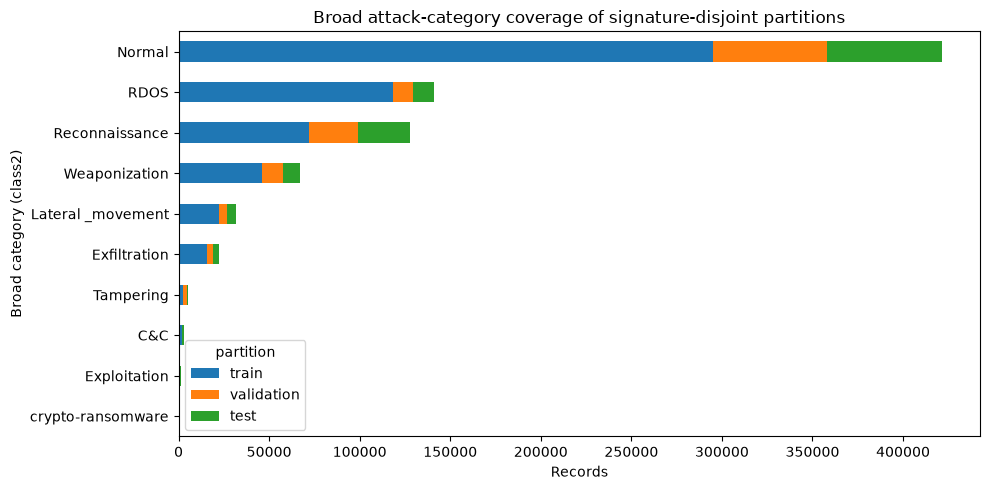

In [4]:
stage_table=pd.crosstab(pd.Series(stages,name='class2'),pd.Series(parts,name='partition'))
stage_table=stage_table.reindex(columns=part_names,fill_value=0)
stage_table['total']=stage_table[part_names].sum(axis=1)
display(stage_table.sort_values('total',ascending=False))
missing_stages=stage_table.loc[(stage_table[['validation','test']]==0).any(axis=1)].index.tolist()
if missing_stages:
    print('WARNING: Missing broad categories in validation/test:',missing_stages)
else:
    print('All observed broad categories represented in validation and test.')
fig,ax=plt.subplots(figsize=(10,5))
stage_table[part_names].sort_values('total' if 'total' in part_names else 'train').plot(kind='barh',stacked=True,ax=ax)
ax.set_xlabel('Records');ax.set_ylabel('Broad category (class2)')
ax.set_title('Broad attack-category coverage of signature-disjoint partitions')
fig.tight_layout();fig.savefig(FIG/'x_iiotid_split_class2_coverage_v1.png',dpi=180);plt.show()

## D. Train-only preprocessing and a Decision Tree baseline

Protocol/service/flags are categorical. Numerical fields are parsed, and missing numerical values are imputed by **training-set medians only**. No IP, timestamp, host telemetry, existing IDS alert, or class label enters the feature matrix. Validation is used to measure the first baseline; the **test set remains sealed**.

In [ ]:
X_model=X.copy()
for c in NUM:
    X_model[c]=pd.to_numeric(X_model[c].replace('<MISSING>',np.nan),errors='coerce').astype(np.float32)
for c in CAT:
    X_model[c]=X_model[c].replace('<MISSING>','__MISSING__').astype(str)
train=parts=='train'; valid=parts=='validation'; test=parts=='test'
assert train.sum()>0 and valid.sum()>0 and test.sum()>0
assert int(y[train].sum())>0 and int(y[valid].sum())>0
# Actual imputation and OHE are fitted *inside* the pipeline on training rows.
prep=ColumnTransformer([
    ('numeric',SimpleImputer(strategy='median',keep_empty_features=True),NUM),
    ('categorical',OneHotEncoder(handle_unknown='ignore'),CAT)
])
model=Pipeline([
    ('preprocess',prep),
    ('tree',DecisionTreeClassifier(max_depth=14,min_samples_leaf=30,
                                   class_weight='balanced',random_state=SEED))
])
model.fit(X_model.loc[train],y[train])
valid_pred=model.predict(X_model.loc[valid])
print('Decision Tree — VALIDATION only')
print(classification_report(y[valid],valid_pred,target_names=['Normal','Attack'],digits=4,zero_division=0))
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(y[valid],valid_pred,
    display_labels=['Normal','Attack'],cmap='Blues',values_format='d',ax=ax)
ax.set_title('Decision Tree: validation confusion matrix')
fig.tight_layout();fig.savefig(FIG/'x_iiotid_dt_validation_confusion_v1.png',dpi=180);plt.show()

## E. Check the missingness shortcut

A **missingness-only** Logistic Regression sees just 11 binary indicators: whether each numerical network field is missing. If this predicts the labels unusually well, accuracy of the Decision Tree may partly reflect data-collection artifacts rather than attack behaviour. It is a comparator, not a deployable APT detector.

In [ ]:
missing_features=X_model[NUM].isna().astype(np.uint8)
missing_clf=LogisticRegression(max_iter=300,random_state=SEED)
missing_clf.fit(missing_features.loc[train],y[train])
missing_pred=missing_clf.predict(missing_features.loc[valid])

def metrics(truth,pred,name):
    tn,fp,fn,tp=confusion_matrix(truth,pred,labels=[0,1]).ravel()
    return {'model':name,'precision_attack':precision_score(truth,pred,zero_division=0),
            'recall_attack':recall_score(truth,pred,zero_division=0),
            'f1_attack':f1_score(truth,pred,zero_division=0),
            'balanced_accuracy':balanced_accuracy_score(truth,pred),
            'false_positive_rate':fp/max(tn+fp,1),
            'validation_records':len(truth)}
comparison=pd.DataFrame([
    metrics(y[valid],valid_pred,'Decision Tree (Core 19)'),
    metrics(y[valid],missing_pred,'Missingness only (11 flags)')
])
display(comparison.round(4))
fig,ax=plt.subplots(figsize=(9,4.5))
comparison.set_index('model')[['recall_attack','f1_attack','balanced_accuracy','false_positive_rate']].T.plot(kind='bar',ax=ax)
ax.set_ylim(0,1);ax.set_ylabel('Score (0–1)');ax.set_xlabel('Validation metric')
ax.set_title('Validation: network model vs. missingness-only shortcut')
ax.tick_params(axis='x',rotation=16)
fig.tight_layout();fig.savefig(FIG/'x_iiotid_dt_vs_missingness_validation_v1.png',dpi=180);plt.show()
print('Do NOT interpret this as a final unseen-session/campaign test.')

## F. Save the research evidence (safe to commit) and preserve test holdout

The original dataset remains unchanged. Save group split ratios, broad category coverage, validation metrics and visualizations. The row-level split manifest stays ignored inside `data/splits`. **No model is serialized yet**; final feature definitions and provenance checks remain pending.

In [ ]:
split_summary_path=AUDIT/'x_iiotid_provisional_group_split_summary_v1.csv'
stage_path=AUDIT/'x_iiotid_provisional_split_class2_coverage_v1.csv'
metrics_path=AUDIT/'x_iiotid_dt_validation_baseline_v1.csv'
json_path=AUDIT/'x_iiotid_provisional_baseline_v1.json'
md_path=DOCS/'X_IIOTID_PROVISIONAL_GROUP_SPLIT_DT_V1.md'
summary.to_csv(split_summary_path)
stage_table.to_csv(stage_path)
comparison.to_csv(metrics_path,index=False)
output={'dataset':CSV.name,'rows':int(N),'signature_groups':len(assignment),
        'features':CORE19,'splits':{p:{'rows':int(summary.loc[p,'rows']),
           'fraction':float(summary.loc[p,'row_fraction']),
           'normal':int(summary.loc[p,'Normal']),
           'attack':int(summary.loc[p,'Attack'])} for p in part_names},
        'signature_overlap_between_splits':0,'missing_class2_in_holdouts':missing_stages,
        'validation_models':comparison.to_dict('records'),'test_scored':False,
        'feature_semantics_verified':False,'capture_session_independence_verified':False,
        'split_method':'Greedy class3-balanced Core-19 BLAKE2b signature grouping; >5% groups train-only',
        'caveats':['Split is provisional, not session-independent',
                   'Identical signatures cannot appear in more than one partition',
                   'Missingness may encode capture conditions',
                   'No APT-campaign-level detection claim']}
json_path.write_text(json.dumps(output,indent=2,ensure_ascii=False),encoding='utf8')
md_path.write_text(f"""# X-IIoTID — provisional Core-19 group split + Decision Tree baseline

- Full CSV rows: **{N:,}**. Unique Core-19 network signatures: **{len(assignment):,}**.
- Train / validation / test row fractions: **{summary.loc['train','row_fraction']:.3%} / {summary.loc['validation','row_fraction']:.3%} / {summary.loc['test','row_fraction']:.3%}**.
- Verified **zero exact Core-19 signature overlap** between partitions.
- Test remains **unevaluated**. Model metrics below are **validation only**.
- Decision Tree validation attack F1: **{float(comparison.iloc[0]['f1_attack']):.4f}**; recall **{float(comparison.iloc[0]['recall_attack']):.4f}**; false positive rate **{float(comparison.iloc[0]['false_positive_rate']):.4f}**.
- Missingness-only validation F1: **{float(comparison.iloc[1]['f1_attack']):.4f}**. This comparator can reveal data-collection shortcuts.
- Broad categories absent from validation/test: **{', '.join(missing_stages) if missing_stages else 'none'}**.

## Methodological limits

This is a provisional **signature-disjoint** benchmark. Repeated flow patterns are kept in only one partition, but data from the same capture session or attack campaign might still occur in multiple partitions. Binary accuracy or class2 attack labels do not prove a complete APT was detected. Full feature semantics, genuine gateway extractability and source/session provenance remain to be verified. Do not tune on the reserved test set.

The original CSV, Notebook 04 SQLite scratch DB, and row-level split manifest are **not** Git-tracked. The outputs in `reports/audits`, `reports/figures` and this document are safe to review for version control.
""",encoding='utf8')
print('Saved reports:',split_summary_path.name,stage_path.name,metrics_path.name,json_path.name)
print('Saved document:',md_path.name)
print('COMPLETE: provisional split + Decision Tree baseline. Held-out test remains unused.')

## G. Commit this completed major research task

Run these in the **PowerShell terminal** from the **Git-connected worktree** after reviewing output files:

```powershell
Set-Location 'D:\J26-CS-336-Network-Flow-V2-Git'
git branch --show-current
# Must be feature/aazaf-network-flow-v2
git add -- network_flow_v2/notebooks/x_iiotid/06_x_iiotid_group_split_dt_baseline.ipynb
git add -- network_flow_v2/reports/audits/x_iiotid_provisional_group_split_summary_v1.csv
git add -- network_flow_v2/reports/audits/x_iiotid_provisional_split_class2_coverage_v1.csv
git add -- network_flow_v2/reports/audits/x_iiotid_dt_validation_baseline_v1.csv
git add -- network_flow_v2/reports/audits/x_iiotid_provisional_baseline_v1.json
git add -- network_flow_v2/reports/figures/x_iiotid_group_split_class_balance_v1.png
git add -- network_flow_v2/reports/figures/x_iiotid_split_class2_coverage_v1.png
git add -- network_flow_v2/reports/figures/x_iiotid_dt_validation_confusion_v1.png
git add -- network_flow_v2/reports/figures/x_iiotid_dt_vs_missingness_validation_v1.png
git add -- network_flow_v2/docs/X_IIOTID_PROVISIONAL_GROUP_SPLIT_DT_V1.md
git add -- network_flow_v2/STATUS.md
git diff --cached --name-only
git diff --cached --check
# If only the intended files are staged:
git commit -m 'research: establish provisional X-IIoTID split and DT baseline'
git push
```

**Send back:** split-summary table, class2-coverage table, and validation model-comparison table. Then we can train **Random Forest / Extra Trees / LightGBM / AdaBoost** on the same frozen split and compare inference costs.